In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

df = pd.read_csv('AmesHousing.csv')
df = df.drop(columns=df.select_dtypes(include=object))
df = df.dropna()

X = df.drop(columns='SalePrice')
Y = df['SalePrice']

M ótimo = 30


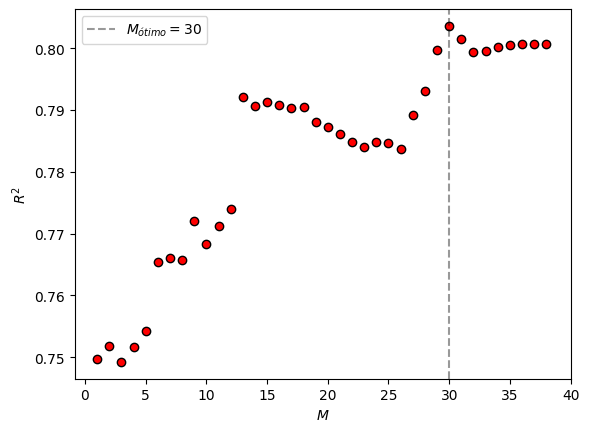

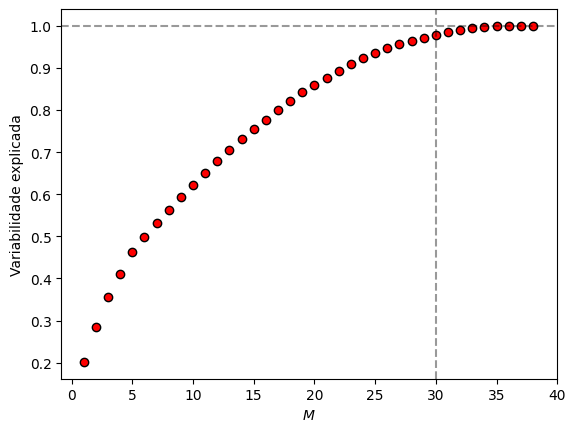

In [126]:
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

model = Pipeline([('OLS',LinearRegression())])
cv = KFold(n_splits=10,shuffle=True,random_state=0)

erros = []
m = np.arange(1,39,1)

for i in range(1,39):

    pca = PCA(n_components=i)
    X_pca = pca.fit_transform(X_norm)

    results = cross_validate(model,X_pca,Y,cv=cv, scoring={'R2':'r2'})

    r2 = results['test_R2']
    erros.append(r2.mean())

M_opm = m[np.argmax(erros)]
print(f'M ótimo = {M_opm}')

plt.figure()
plt.axvline(x=30,ls='--',color='black',alpha=0.4,label=rf'$M_{{ótimo}} = {M_opm}$')
plt.scatter(m,erros,color='red',edgecolors='black')
plt.xlabel(r'$M$')
plt.ylabel(r'$R^2$')
plt.legend()
plt.xticks(np.arange(0,41,5))
plt.show()

var_acumulada = np.cumsum(pca.explained_variance_ratio_)

plt.figure()
plt.axhline(y=1,ls='--',color='black',alpha=0.4)
plt.axvline(x=30,ls='--',color='black',alpha=0.4,label=rf'$M_{{ótimo}} = {M_opm}$')
plt.scatter(range(1, len(var_acumulada) + 1), var_acumulada,color='red',edgecolors='black')
plt.xlabel(r"$M$")
plt.ylabel("Variabilidade explicada")
plt.xticks(np.arange(0,41,5))
plt.show()

In [124]:
pca = PCA(n_components=M_opm)
X_pca = pca.fit_transform(X_norm)

results = cross_validate(model,X,Y,cv=cv,scoring={'RMSE':'neg_root_mean_squared_error', 'R2':'r2'})

rmse = -results['test_RMSE']
r2 = results['test_R2']

print('\nResultado via Linear Regression:')
print(f'RMSE: {rmse.mean():.4f} ± {rmse.std():.4f}')
print(f'R²:   {r2.mean():.4f} ± {r2.std():.4f}')

results = cross_validate(model,X_pca,Y,cv=cv,scoring={'RMSE':'neg_root_mean_squared_error', 'R2':'r2'})

rmse = -results['test_RMSE']
r2 = results['test_R2']

print('\nResultado via PCR:')
print(f'RMSE: {rmse.mean():.4f} ± {rmse.std():.4f}')
print(f'R²:   {r2.mean():.4f} ± {r2.std():.4f}')


Resultado via Linear Regression:
RMSE: 35637.6316 ± 10774.7155
R²:   0.8007 ± 0.1320

Resultado via PCR:
RMSE: 35529.1977 ± 10150.2661
R²:   0.8036 ± 0.1211
